# Codveda ML Internship - Level 3 (Advanced)
- Task 1: Random Forest Classifier
- Task 2: Support Vector Machine (SVM)
- Task 3: Neural Network with TensorFlow/Keras (MNIST)

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report)

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X.shape)

(569, 30)


---
# Task 1: Random Forest Classifier
Dataset: Breast Cancer Wisconsin (30 features).

### Hyperparameter tuning (GridSearchCV with 5-fold cross-validation)

In [2]:
param_grid = {"n_estimators": [100, 200, 300], "max_depth": [None, 5, 10], "min_samples_split": [2, 5]}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 3))
rf = grid.best_estimator_

Best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 : 0.968


### Cross-validation and test-set metrics

In [3]:
cv = cross_val_score(rf, X_train, y_train, cv=5, scoring="f1")
print("CV F1 scores:", cv.round(3), "| mean:", cv.mean().round(3), "+/-", cv.std().round(3))
p = rf.predict(X_test)
print(classification_report(y_test, p, target_names=data.target_names))

CV F1 scores: [0.974 0.991 0.948 0.956 0.973] | mean: 0.968 +/- 0.015
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### Feature importance

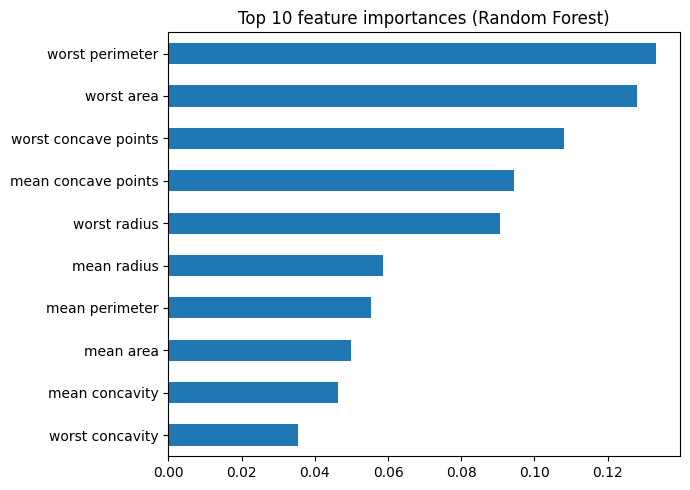

In [4]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind="barh", figsize=(7, 5), title="Top 10 feature importances (Random Forest)")
plt.tight_layout(); plt.savefig("rf_feature_importance.png", dpi=150); plt.show()

---
# Task 2: Support Vector Machine (SVM)
Same dataset, binary classification. SVMs need scaled features, so scaling is part of each pipeline.

In [5]:
results, models = [], {}
for kernel in ["linear", "rbf"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, probability=True, random_state=42)).fit(X_train, y_train)
    p = model.predict(X_test); s = model.predict_proba(X_test)[:, 1]
    models[kernel] = (model, s)
    results.append({"kernel": kernel, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                    "recall": recall_score(y_test, p), "AUC": roc_auc_score(y_test, s)})
pd.DataFrame(results).set_index("kernel").round(3)

,accuracy,precision,recall,AUC
kernel,,,,
linear,0.974,0.986,0.972,0.996
rbf,0.982,0.986,0.986,0.995


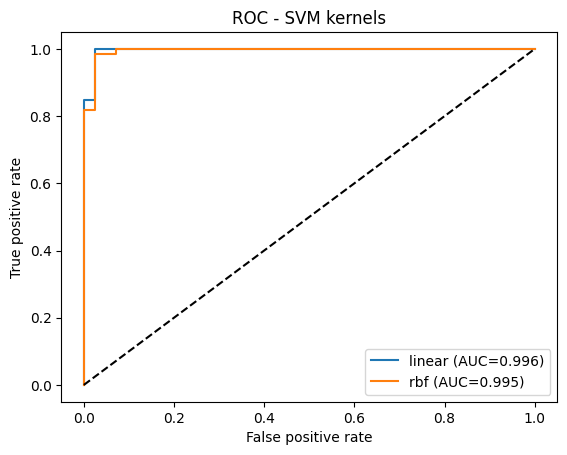

In [6]:
for kernel, (model, s) in models.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{kernel} (AUC={roc_auc_score(y_test, s):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC - SVM kernels"); plt.legend(); plt.savefig("svm_roc.png", dpi=150); plt.show()

### Decision boundary
The data has 30 features, so I project to 2D with PCA only for visualization (the metrics above use all 30 features).

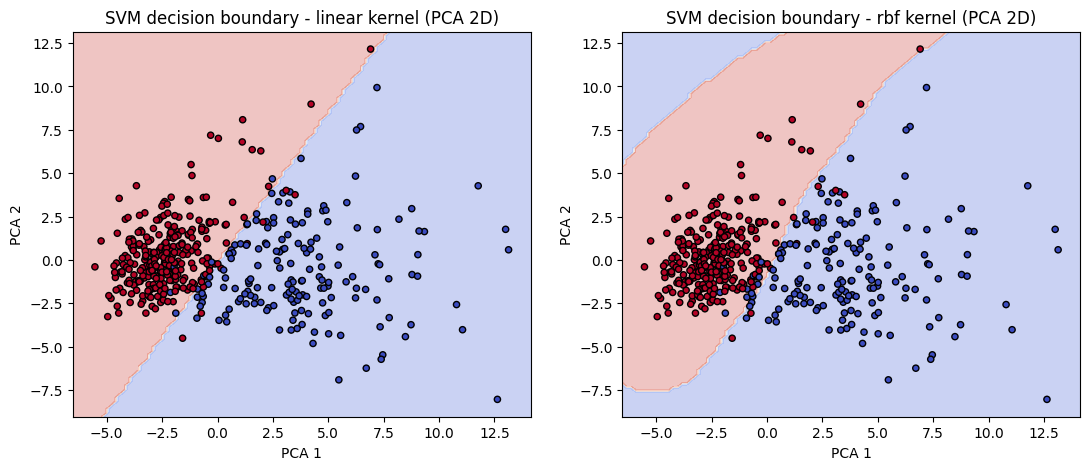

In [7]:
scaler = StandardScaler().fit(X_train)
pca = PCA(n_components=2).fit(scaler.transform(X_train))
Z_train = pca.transform(scaler.transform(X_train))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    clf = SVC(kernel=kernel).fit(Z_train, y_train)
    DecisionBoundaryDisplay.from_estimator(clf, Z_train, response_method="predict", alpha=0.3, cmap="coolwarm", ax=ax)
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_title(f"SVM decision boundary - {kernel} kernel (PCA 2D)")
    ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2")
plt.savefig("svm_decision_boundary.png", dpi=150); plt.show()

---
# Task 3: Neural Network with TensorFlow/Keras (MNIST)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (10000, 28, 28)


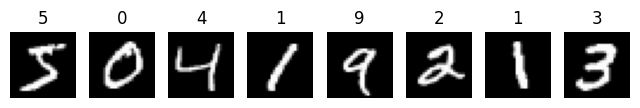

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

(x_train, y_train_d), (x_test, y_test_d) = keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print(x_train.shape, x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1); plt.imshow(x_train[i], cmap="gray"); plt.title(y_train_d[i]); plt.axis("off")
plt.show()

### Architecture: Input (28x28) -> Flatten -> Dense(128, ReLU) -> Dropout -> Dense(64, ReLU) -> Dense(10, softmax)

In [9]:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Training (backpropagation is performed automatically by `fit`, with the Adam optimizer)

In [10]:
history = model.fit(x_train, y_train_d, epochs=10, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/10
422/422 - 4s - 10ms/step - accuracy: 0.8829 - loss: 0.4036 - val_accuracy: 0.9615 - val_loss: 0.1382
Epoch 2/10
422/422 - 2s - 5ms/step - accuracy: 0.9476 - loss: 0.1761 - val_accuracy: 0.9708 - val_loss: 0.1032
Epoch 3/10
422/422 - 2s - 6ms/step - accuracy: 0.9615 - loss: 0.1296 - val_accuracy: 0.9743 - val_loss: 0.0885
Epoch 4/10
422/422 - 2s - 5ms/step - accuracy: 0.9667 - loss: 0.1088 - val_accuracy: 0.9775 - val_loss: 0.0777
Epoch 5/10
422/422 - 3s - 7ms/step - accuracy: 0.9719 - loss: 0.0911 - val_accuracy: 0.9788 - val_loss: 0.0752
Epoch 6/10
422/422 - 5s - 12ms/step - accuracy: 0.9754 - loss: 0.0795 - val_accuracy: 0.9795 - val_loss: 0.0733
Epoch 7/10
422/422 - 2s - 5ms/step - accuracy: 0.9777 - loss: 0.0697 - val_accuracy: 0.9795 - val_loss: 0.0717
Epoch 8/10
422/422 - 2s - 5ms/step - accuracy: 0.9805 - loss: 0.0625 - val_accuracy: 0.9808 - val_loss: 0.0690
Epoch 9/10
422/422 - 3s - 7ms/step - accuracy: 0.9817 - loss: 0.0572 - val_accuracy: 0.9815 - val_loss: 0.0694

Test accuracy: 0.9771 | Test loss: 0.0739


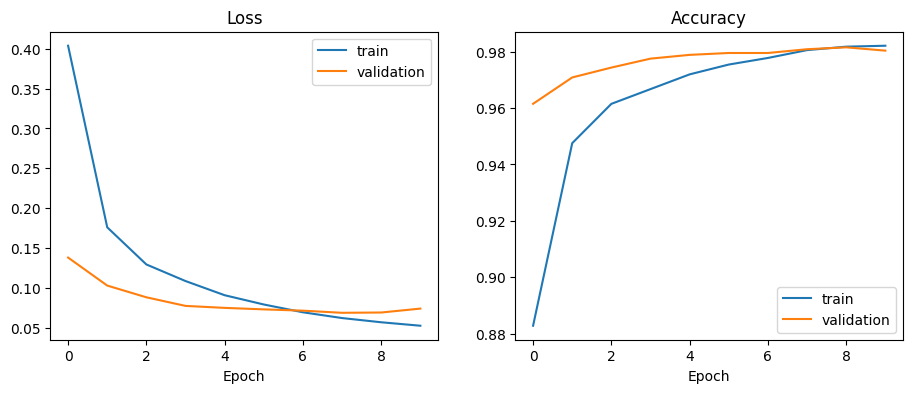

In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test_d, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.savefig("nn_training_curves.png", dpi=150); plt.show()

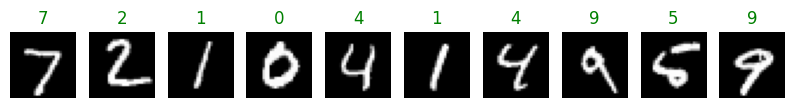

In [12]:
pred = model.predict(x_test[:10], verbose=0).argmax(axis=1)
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1); plt.imshow(x_test[i], cmap="gray")
    plt.title(f"{pred[i]}", color="green" if pred[i] == y_test_d[i] else "red"); plt.axis("off")
plt.show()